<a id="CME538---Introduction-to-Data-Science"></a>
<a id="cme538---introduction-to-data-science"></a>
<h1>CME538 - Introduction to Data Science</h1>
<a id="Lecture-8.2---Regularization"></a>
<a id="lecture-82---regularization"></a>
<h2>Lecture 8.2 - Regularization</h2>
<p>Fit the dam measurements with polynomial models, then compare Ridge and Lasso penalties. Return to the game-classification example from Week 7 to see how regularization changes predicted probabilities.</p>
<p>Central question: How does regularization change fitted coefficients and predictions, and how should we choose its strength?</p>
<p>You will compare polynomial fits, explain why feature units matter, inspect coefficient shrinkage and feature removal, and choose penalty strengths using validation results. You will also separate the fitting objective from prediction error.</p>
<h3>Lecture Structure</h3>
<ol>
<li><a href="#section1">1. Import Dam Data</a></li>
<li><a href="#section2">2. Standardization</a></li>
<li><a href="#section3">3. Ridge Regularization</a></li>
<li><a href="#section4">4. Lasso Regularization</a></li>
<li><a href="#section5">5. Regularized Logistic Regression</a></li>
<li><a href="#section6">6. Evaluating Regularized Models</a></li>
</ol>
<p><a href="#summary">Lecture summary</a></p>
<h3>Data</h3>
<p>The supplied <a href="water_large.csv">dam data</a> contain water level change in metres and daily water flow in litres. The supplied <a href="nba.csv">NBA box scores</a> are the 2017-2018 season data used in Week 7, from <a href="https://www.nba.com/stats/">NBA Stats</a>. Each game contributes two team rows.</p>

<a id="Setup-Notebook"></a>
<a id="setup-notebook"></a>
<h2>Setup Notebook</h2>
<p>Run the cells in order. This notebook uses NumPy, pandas, Matplotlib, and scikit-learn, with the supplied CSV file. The local <code>utils.py</code> file draws the comparison figures. Feature construction, fitting, and evaluation remain visible in the cells.</p>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, log_loss, accuracy_score
from utils import (plot_ridge_errors, plot_ridge_curves, plot_unit_effects,
                   plot_coefficient_paths, plot_lasso_comparison, plot_logistic_regularization)

%matplotlib inline

# Shared CME538 plot style
FTE_BLUE = '#30A2DA'
FTE_RED = '#FC4F30'
FTE_YELLOW = '#E5AE38'
FTE_GREEN = '#6D904F'
FTE_GRAY = '#8B8B8B'
FTE_PURPLE = '#810F7C'
FTE_COLORS = [FTE_BLUE, FTE_RED, FTE_YELLOW, FTE_GREEN, FTE_GRAY, FTE_PURPLE]
PLOT_TITLE_SIZE = 16
AXIS_LABEL_SIZE = 12
TICK_LABEL_SIZE = 11
LEGEND_SIZE = 10

plt.style.use('fivethirtyeight')
plt.rcParams.update({
    'axes.prop_cycle': cycler(color=FTE_COLORS),
    'axes.titlesize': PLOT_TITLE_SIZE,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.labelsize': AXIS_LABEL_SIZE,
    'xtick.labelsize': TICK_LABEL_SIZE,
    'ytick.labelsize': TICK_LABEL_SIZE,
    'legend.fontsize': LEGEND_SIZE,
    'figure.titlesize': PLOT_TITLE_SIZE,
    'figure.figsize': (9, 5),
    'figure.dpi': 110,
    'lines.linewidth': 1.5,
})
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 10)

RANDOM_STATE = 538
pd.set_option('display.precision', 3)
print('Random seed:', RANDOM_STATE)

Random seed: 538


<a id='section1'></a>
<a id="Import-Dam-Data"></a>
<a id="import-dam-data"></a>
<h2>1. Import Dam Data</h2>
<p>Question: Does a straight line capture the pattern in the dam measurements?</p>

In [2]:
water = pd.read_csv('water_large.csv')
water.head()

,water_level_change,water_flow
0,-15.937,6.042e+10
1,-29.153,3.321e+10
2,36.190,9.727e+11
3,37.492,1.043e+12
4,-48.059,7.952e+10


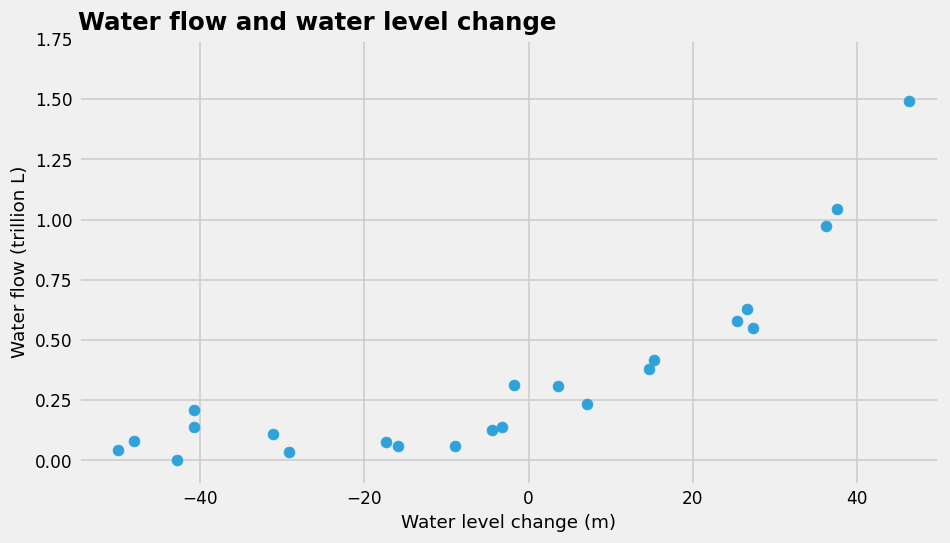

In [3]:
fig, ax = plt.subplots()
ax.scatter(water['water_level_change'], water['water_flow'] / 1e12, s=50)
ax.set(title='Water flow and water level change',
       xlabel='Water level change (m)', ylabel='Water flow (trillion L)',
       xlim=(None, 50), ylim=(-0.1, 1.75))
plt.show()

<h3>Degree 1 polynomial</h3>

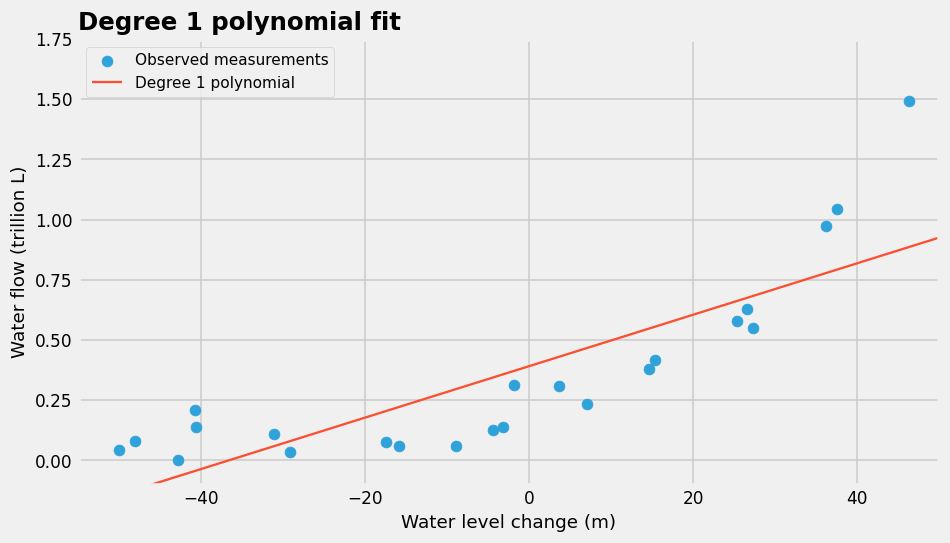

In [4]:
deg = 1
trans = PolynomialFeatures(degree=deg)
X = trans.fit_transform(water[['water_level_change']].to_numpy())
clf = LinearRegression(fit_intercept=False).fit(X, water[['water_flow']])
xs = np.linspace(water['water_level_change'].min(), 50, 1000).reshape(-1, 1)
ys = clf.predict(trans.transform(xs))

fig, ax = plt.subplots()
ax.scatter(water['water_level_change'], water['water_flow'] / 1e12,
           s=50, label='Observed measurements')
ax.plot(xs, ys / 1e12, color=FTE_RED, label=f'Degree {deg} polynomial')
ax.set(title=f'Degree {deg} polynomial fit',
       xlabel='Water level change (m)', ylabel='Water flow (trillion L)',
       xlim=(None, 50), ylim=(-0.1, 1.75))
ax.legend(loc='upper left')
plt.show()

<p>The straight line misses the curvature in the observed measurements.</p>

<h3>Degree 2 polynomial</h3>

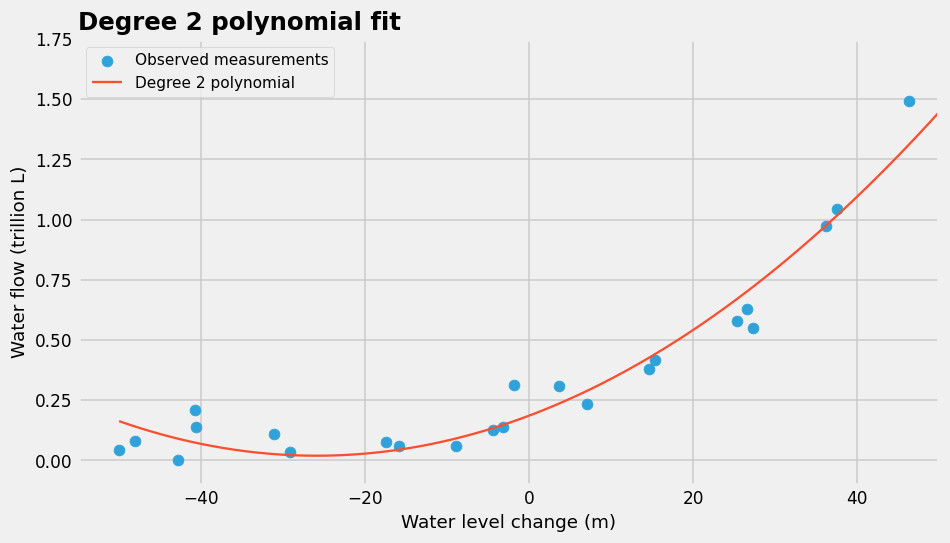

In [5]:
deg = 2
trans = PolynomialFeatures(degree=deg)
X = trans.fit_transform(water[['water_level_change']].to_numpy())
clf = LinearRegression(fit_intercept=False).fit(X, water[['water_flow']])
xs = np.linspace(water['water_level_change'].min(), 50, 1000).reshape(-1, 1)
ys = clf.predict(trans.transform(xs))

fig, ax = plt.subplots()
ax.scatter(water['water_level_change'], water['water_flow'] / 1e12,
           s=50, label='Observed measurements')
ax.plot(xs, ys / 1e12, color=FTE_RED, label=f'Degree {deg} polynomial')
ax.set(title=f'Degree {deg} polynomial fit',
       xlabel='Water level change (m)', ylabel='Water flow (trillion L)',
       xlim=(None, 50), ylim=(-0.1, 1.75))
ax.legend(loc='upper left')
plt.show()

<p>The quadratic curve follows the upward bend more closely than the straight line.</p>

<h3>Degree 8 polynomial</h3>

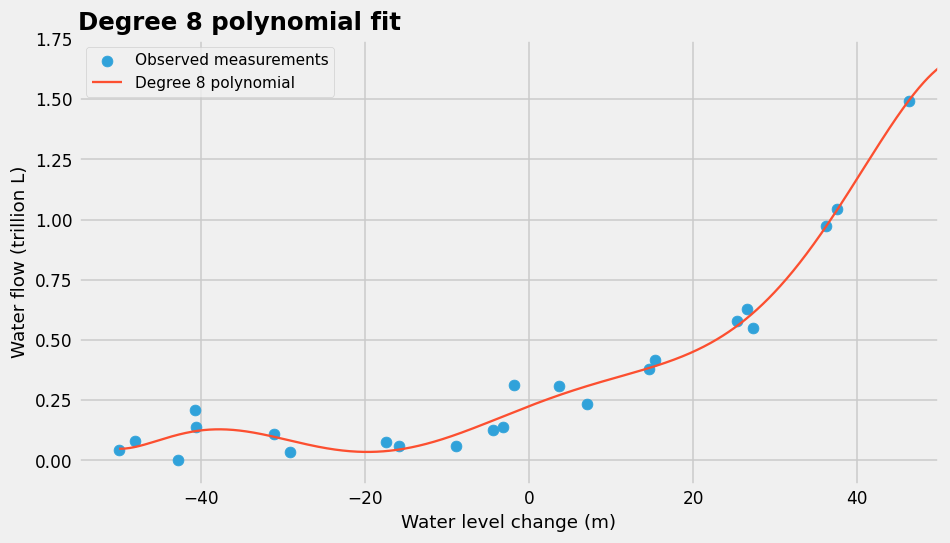

In [6]:
deg = 8
trans = PolynomialFeatures(degree=deg)
X = trans.fit_transform(water[['water_level_change']].to_numpy())
clf = LinearRegression(fit_intercept=False).fit(X, water[['water_flow']])
xs = np.linspace(water['water_level_change'].min(), 50, 1000).reshape(-1, 1)
ys = clf.predict(trans.transform(xs))

fig, ax = plt.subplots()
ax.scatter(water['water_level_change'], water['water_flow'] / 1e12,
           s=50, label='Observed measurements')
ax.plot(xs, ys / 1e12, color=FTE_RED, label=f'Degree {deg} polynomial')
ax.set(title=f'Degree {deg} polynomial fit',
       xlabel='Water level change (m)', ylabel='Water flow (trillion L)',
       xlim=(None, 50), ylim=(-0.1, 1.75))
ax.legend(loc='upper left')
plt.show()

<p>The higher-degree curve follows local changes in the observed measurements. These bends also show the additional flexibility of the model.</p>

<h3>Degree 12 polynomial</h3>

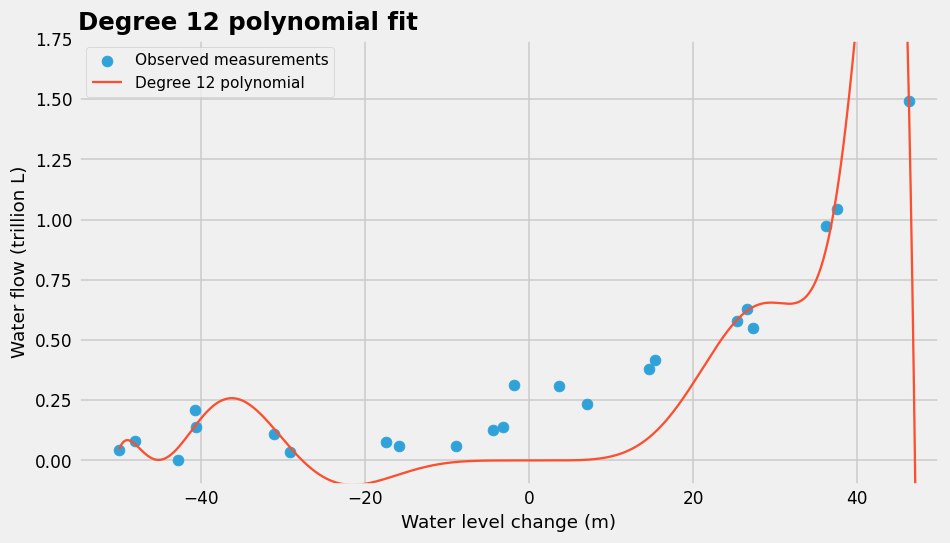

In [7]:
deg = 12
trans = PolynomialFeatures(degree=deg)
X = trans.fit_transform(water[['water_level_change']].to_numpy())
clf = LinearRegression(fit_intercept=False).fit(X, water[['water_flow']])
xs = np.linspace(water['water_level_change'].min(), 50, 1000).reshape(-1, 1)
ys = clf.predict(trans.transform(xs))

fig, ax = plt.subplots()
ax.scatter(water['water_level_change'], water['water_flow'] / 1e12,
           s=50, label='Observed measurements')
ax.plot(xs, ys / 1e12, color=FTE_RED, label=f'Degree {deg} polynomial')
ax.set(title=f'Degree {deg} polynomial fit',
       xlabel='Water level change (m)', ylabel='Water flow (trillion L)',
       xlim=(None, 50), ylim=(-0.1, 1.75))
ax.legend(loc='upper left')
plt.show()

<p>The degree 12 curve bends sharply near the largest water level changes. A close fit to these measurements alone does not establish performance on new days.</p>

<p>Takeaway: Increasing polynomial degree gives the fitted curve more flexibility. Use held-out observations to judge whether the added flexibility improves prediction.</p>
<p>Return to the slides at Intuition, where the regularization penalty changes the fitting objective.</p>

<a id="section2"></a>
<h2>2. Standardization</h2>
<p>Question: Should changing water level units from metres to kilometres change a fitted prediction?</p>
<p>The measurements describe the same physical quantities in either unit. A coefficient penalty depends on numerical coefficient values, so units affect the penalty unless we first standardize the features.</p>
<p>Split the 23 measurements into 16 training rows and 7 validation rows. Keep these rows fixed for all dam-model comparisons. This random split illustrates model selection. Forecasting future days would require dates and a split in time order.</p>
<p>Use a straight-line model here to isolate the effect of units. Water flow remains in trillion litres. The next section returns to degree 8 polynomial features.</p>

In [8]:
training, validation = train_test_split(water, test_size=0.3, random_state=RANDOM_STATE)
y_train = training['water_flow'] / 1e12
y_validation = validation['water_flow'] / 1e12
water_grid = pd.DataFrame({'water_level_change': np.linspace(
    water['water_level_change'].min(), water['water_level_change'].max(), 401)})
unit_features = pd.DataFrame({
    'Metres': training['water_level_change'],
    'Kilometres': training['water_level_change'] / 1000,
})
print('Training rows:', len(training), '| Validation rows:', len(validation))
unit_features.agg(['mean', 'std'])

Training rows: 16 | Validation rows: 7


,Metres,Kilometres
mean,-5.980,-0.006
std,32.507,0.033


<p>Expressing the feature in kilometres divides both its mean and standard deviation by 1,000. Fit the same Ridge penalty, <code>alpha=1</code>, before and after standardization. Each scaler learns its mean and standard deviation from training rows only.</p>

In [9]:
unit_rows = []
unit_curves = {}
unit_predictions = {}
for standardized in [False, True]:
    for unit, divisor in [('Metres', 1), ('Kilometres', 1000)]:
        unit_train = training[['water_level_change']] / divisor
        unit_validation = validation[['water_level_change']] / divisor
        unit_grid = water_grid / divisor
        if standardized:
            unit_scaler = StandardScaler()
            unit_train = unit_scaler.fit_transform(unit_train)
            unit_validation = unit_scaler.transform(unit_validation)
            unit_grid = unit_scaler.transform(unit_grid)
        unit_model = Ridge(alpha=1.0)
        unit_model.fit(unit_train, y_train)
        predictions = unit_model.predict(unit_validation)
        rmse = mean_squared_error(y_validation, predictions)**0.5
        unit_rows.append([standardized, unit, unit_model.coef_[0], rmse])
        unit_curves[(standardized, unit)] = unit_model.predict(unit_grid)
        unit_predictions[(standardized, unit)] = predictions
unit_results = pd.DataFrame(unit_rows, columns=[
    'Standardized', 'Original unit', 'Coefficient', 'Validation RMSE'])
unit_results

,Standardized,Original unit,Coefficient,Validation RMSE
0,False,Metres,0.010,0.218
1,False,Kilometres,0.160,0.347
2,True,Metres,0.304,0.221
3,True,Kilometres,0.304,0.221


<p>Without standardization, the kilometre representation produces a much flatter fitted line and a larger validation error. After standardization, both representations give the same coefficient and predictions, apart from numerical rounding. The intercept remains outside the coefficient penalty.</p>

Largest difference after standardization: 1.11e-16


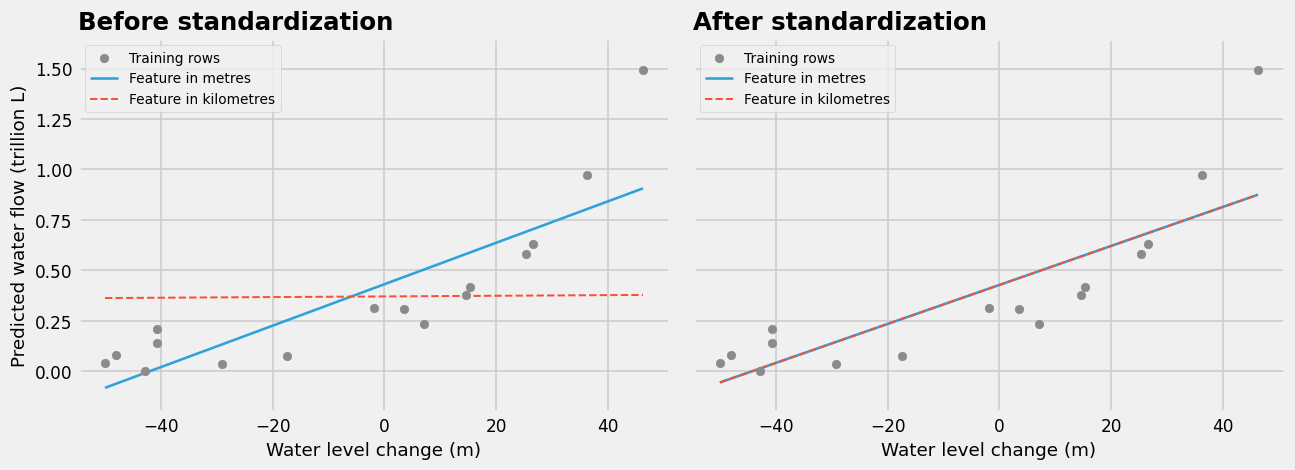

In [10]:
largest_difference = np.max(np.abs(
    unit_predictions[(True, 'Metres')] - unit_predictions[(True, 'Kilometres')]))
print('Largest difference after standardization:', f'{largest_difference:.2e}')
plot_unit_effects(training, water_grid, unit_curves)
plt.show()

<p>Takeaway: A change of units should not change the prediction problem. Standardize features before applying coefficient penalties, and reuse the training transformation for validation rows.</p>
<p>Return to the slides at L2 regularization: Ridge regression.</p>

<a id="section3"></a>
<h2>3. Ridge Regularization</h2>
<p>Question: How does the penalty strength change a degree 8 model and its validation error?</p>
<p>Return to degree 8 polynomial features. Reuse the same 16 training rows and 7 validation rows from Section 2. Keep the split and degree fixed while changing the penalty strength.</p>
<p>Standardize each polynomial feature using the training rows. Apply those same means and standard deviations to validation rows and plotting locations. Express water flow in trillion litres to keep the output readable.</p>
<h3>Fit the unregularized comparison</h3>
<p>Fit a fresh degree 8 model using only the training rows. RMSE measures prediction error in the same units as water flow.</p>

In [11]:
x_grid = pd.DataFrame({'water_level_change': np.linspace(
    water['water_level_change'].min(), water['water_level_change'].max(), 401)})

polynomial = PolynomialFeatures(degree=8, include_bias=False)
X_train = polynomial.fit_transform(training[['water_level_change']])
X_validation = polynomial.transform(validation[['water_level_change']])
X_grid = polynomial.transform(x_grid)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_validation_scaled = scaler.transform(X_validation)
X_grid_scaled = scaler.transform(X_grid)

unregularized = LinearRegression()
unregularized.fit(X_train_scaled, y_train)
baseline_train_rmse = mean_squared_error(y_train, unregularized.predict(X_train_scaled))**0.5
baseline_validation_rmse = mean_squared_error(y_validation, unregularized.predict(X_validation_scaled))**0.5
print('Training rows:', len(training), '| Validation rows:', len(validation))
print('Unregularized training RMSE (trillion L):', round(baseline_train_rmse, 3))
print('Unregularized validation RMSE (trillion L):', round(baseline_validation_rmse, 3))

Training rows: 16 | Validation rows: 7
Unregularized training RMSE (trillion L): 0.045
Unregularized validation RMSE (trillion L): 0.099


<p>The unregularized model has training RMSE of about 0.045 trillion litres and validation RMSE of about 0.099 trillion litres. The validation rows have not entered the fitted model or scaler.</p>
<h3>Increase the Ridge penalty</h3>
<p>Ridge adds a penalty on the sum of squared coefficients. The slides write the penalty strength as $\lambda$. Scikit-learn calls this setting <code>alpha</code>. Its numerical scale depends on the loss convention and feature scaling.</p>
<p>Compare five penalty strengths. Report ordinary prediction RMSE without adding the penalty. The coefficient norm is $\sqrt{\sum_j w_j^2}$, using coefficients of the standardized features and excluding the intercept. A smaller norm indicates smaller coefficients overall.</p>

In [12]:
alphas = [0.01, 0.1, 1.0, 10.0, 100.0]
ridge_rows = [['Unregularized', 0.0, baseline_train_rmse, baseline_validation_rmse,
               np.sqrt(np.sum(unregularized.coef_**2))]]
ridge_curves = {0.0: unregularized.predict(X_grid_scaled)}
ridge_models = {0.0: unregularized}
ridge_coefficients = {}
for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)
    training_predictions = model.predict(X_train_scaled)
    validation_predictions = model.predict(X_validation_scaled)
    training_rmse = mean_squared_error(y_train, training_predictions)**0.5
    validation_rmse = mean_squared_error(y_validation, validation_predictions)**0.5
    coefficient_norm = np.sqrt(np.sum(model.coef_**2))
    ridge_rows.append(['Ridge', alpha, training_rmse, validation_rmse, coefficient_norm])
    ridge_curves[alpha] = model.predict(X_grid_scaled)
    ridge_models[alpha] = model
    ridge_coefficients[alpha] = model.coef_.copy()

ridge_results = pd.DataFrame(ridge_rows, columns=[
    'Model', 'Alpha', 'Training RMSE', 'Validation RMSE', 'Coefficient norm'])
ridge_results

,Model,Alpha,Training RMSE,Validation RMSE,Coefficient norm
0,Unregularized,0.00,0.045,0.099,5.345
1,Ridge,0.01,0.050,0.078,0.529
2,Ridge,0.10,0.053,0.076,0.360
3,Ridge,1.00,0.062,0.100,0.289
4,Ridge,10.00,0.122,0.185,0.200
5,Ridge,100.00,0.290,0.306,0.065


<h3>Track the coefficients as the penalty grows</h3>
<p>Each line follows one coefficient of a standardized polynomial feature. The intercept is excluded. The features are strongly related, so individual coefficients need not move toward zero at every step. The overall coefficient norm decreases as the penalty grows.</p>

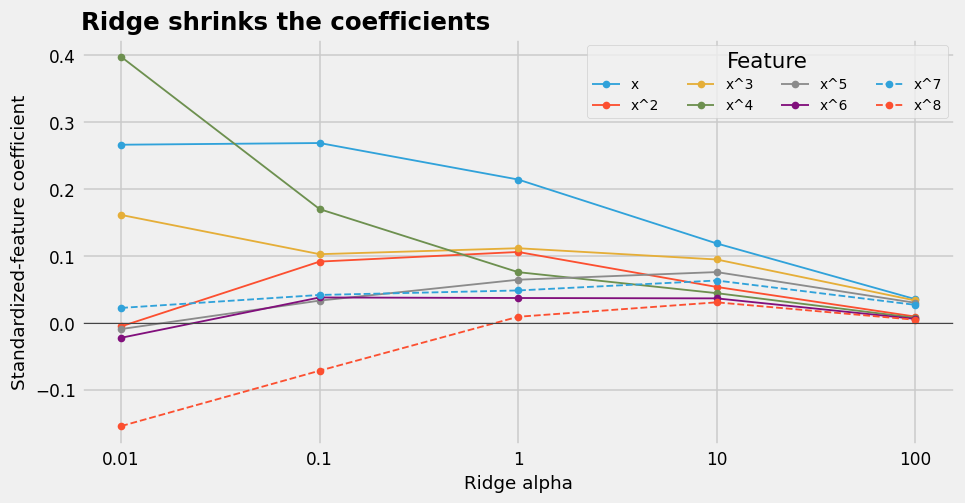

In [13]:
feature_labels = ['x', 'x^2', 'x^3', 'x^4', 'x^5', 'x^6', 'x^7', 'x^8']
ridge_path = pd.DataFrame(ridge_coefficients, index=feature_labels).T
plot_coefficient_paths(ridge_path, 'Ridge shrinks the coefficients', 'Ridge alpha')
plt.show()

<p>Ridge reduces coefficient sizes while retaining all eight features in this example. Small coefficients and exactly zero coefficients have different implications for which features enter a prediction.</p>

<p>The coefficient norm falls from about 5.345 without a penalty to 0.360 at <code>alpha=0.1</code>. Training error rises as the penalty strengthens. Validation error first improves, then rises when the penalty becomes too strong.</p>
<h3>Choose a penalty using validation error</h3>
<p>Choose the candidate with the lowest validation RMSE. The plot uses a logarithmic alpha axis because the positive values differ by factors of ten. Horizontal lines show the unregularized errors.</p>

Selected alpha: 0.1
Validation RMSE (trillion L): 0.076


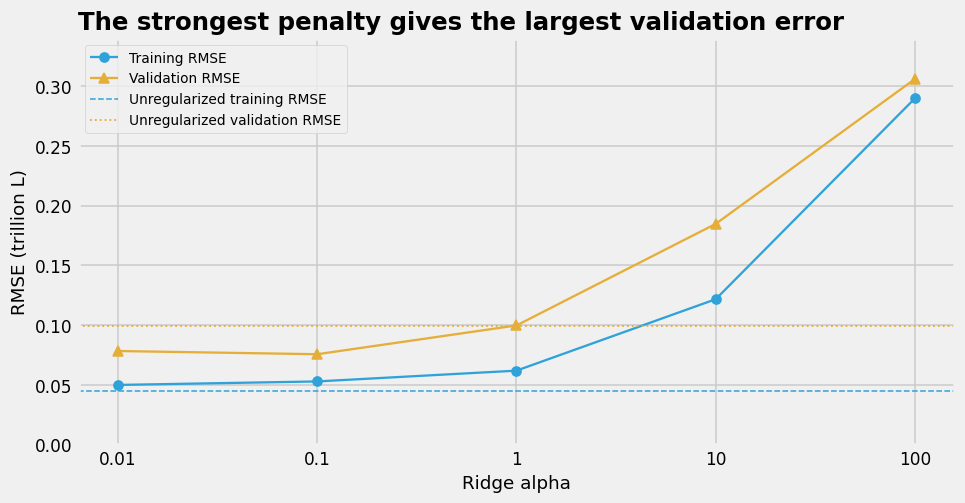

In [14]:
best_row = ridge_results.loc[ridge_results['Validation RMSE'].idxmin()]
best_alpha = float(best_row['Alpha'])
best_ridge = ridge_models[best_alpha]
print('Selected alpha:', best_alpha)
print('Validation RMSE (trillion L):', round(best_row['Validation RMSE'], 3))
plot_ridge_errors(ridge_results)
plt.show()

<p>Among these candidates, <code>alpha=0.1</code> gives the lowest validation RMSE, about 0.076 trillion litres. This choice applies to this split. Seven validation observations give limited evidence about future performance.</p>
<p>Compare the selected curve with the unregularized curve and the strongest penalty. All three models use the same degree 8 features and the same training rows.</p>

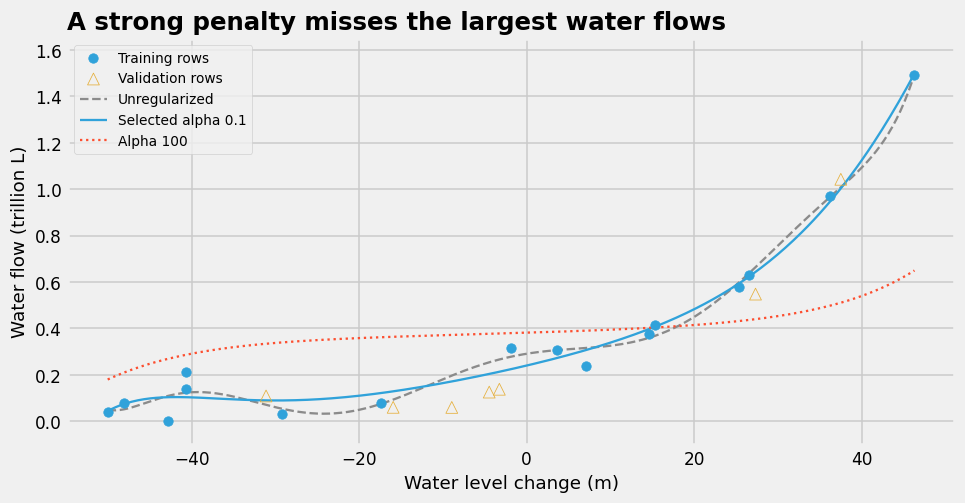

In [15]:
plot_ridge_curves(training, validation, x_grid, ridge_curves, best_alpha)
plt.show()

<p>The strongest penalty flattens the fitted relationship and misses the largest water flows. The selected penalty keeps the main upward pattern while shrinking the coefficients substantially.</p>
<p>Takeaway: A stronger penalty produces smaller coefficients, but the strongest penalty does not give the lowest validation error. Use validation results to choose the strength, then evaluate the chosen procedure on a separate final test set.</p>
<p>Return to the slides at L1 regularization: Lasso regression.</p>

<a id="section4"></a>
<h2>4. Lasso Regularization</h2>
<p>Question: How does Lasso change which polynomial features contribute to a prediction?</p>
<p>Lasso penalizes the sum of absolute coefficient values. Reuse the same degree 8 features, training scaler, and training/validation rows as Ridge. Compare five Lasso strengths. Ridge and Lasso use different penalties and loss conventions, so the same numerical <code>alpha</code> does not mean the same penalty strength.</p>
<p>The intercept stays outside the penalty. Count nonzero coefficients to see how many polynomial features remain in each model.</p>

In [16]:
lasso_alphas = [0.0001, 0.001, 0.01, 0.1, 1.0]
lasso_rows = []
lasso_models = {}
lasso_coefficients = {}
for alpha in lasso_alphas:
    lasso_model = Lasso(alpha=alpha, max_iter=100000, tol=1e-7)
    lasso_model.fit(X_train_scaled, y_train)
    train_rmse = mean_squared_error(y_train, lasso_model.predict(X_train_scaled))**0.5
    val_rmse = mean_squared_error(y_validation, lasso_model.predict(X_validation_scaled))**0.5
    features_used = np.count_nonzero(lasso_model.coef_)
    lasso_rows.append([alpha, train_rmse, val_rmse, features_used])
    lasso_models[alpha] = lasso_model
    lasso_coefficients[alpha] = lasso_model.coef_.copy()
lasso_results = pd.DataFrame(lasso_rows, columns=[
    'Alpha', 'Training RMSE', 'Validation RMSE', 'Features used'])
lasso_results

,Alpha,Training RMSE,Validation RMSE,Features used
0,1.000e-04,0.050,0.079,6
1,1.000e-03,0.053,0.075,6
2,1.000e-02,0.060,0.088,5
3,1.000e-01,0.204,0.228,3
4,1.000e+00,0.385,0.350,0


<p>The strongest penalty sets every slope coefficient to zero, leaving only the intercept. The model then predicts the same water flow for every observation. Lower penalties retain more features, but the weakest penalty does not give the lowest validation error on this split.</p>

Selected Lasso alpha: 0.001
Validation RMSE (trillion L): 0.075


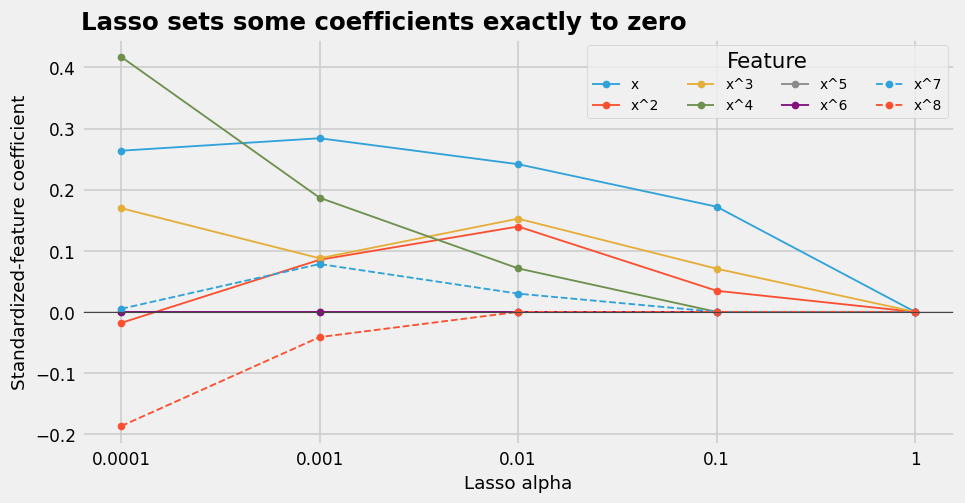

In [17]:
best_lasso_row = lasso_results.loc[lasso_results['Validation RMSE'].idxmin()]
best_lasso_alpha = float(best_lasso_row['Alpha'])
best_lasso = lasso_models[best_lasso_alpha]
print('Selected Lasso alpha:', best_lasso_alpha)
print('Validation RMSE (trillion L):', round(best_lasso_row['Validation RMSE'], 3))
lasso_path = pd.DataFrame(lasso_coefficients, index=feature_labels).T
plot_coefficient_paths(lasso_path, 'Lasso sets some coefficients exactly to zero', 'Lasso alpha')
plt.show()

<p>Validation selects <code>alpha=0.001</code>, with RMSE about 0.075 trillion litres. Six coefficients remain nonzero. Compare those coefficients with the validation-selected Ridge model.</p>

In [18]:
coefficient_comparison = pd.DataFrame({
    'Ridge': best_ridge.coef_,
    'Lasso': best_lasso.coef_,
}, index=feature_labels)
coefficient_comparison.index.name = 'Standardized feature'
coefficient_comparison

,Ridge,Lasso
Standardized feature,,
x,0.269,0.284
x^2,0.092,0.085
x^3,0.103,0.088
x^4,0.170,0.187
x^5,0.033,0.000
x^6,0.038,0.000
x^7,0.042,0.078
x^8,-0.072,-0.041


<p>Lasso removes the standardized $x^5$ and $x^6$ terms in this fit. Ridge retains both. The polynomial features are strongly correlated, so a zero coefficient does not establish that a physical process lacks the corresponding effect.</p>

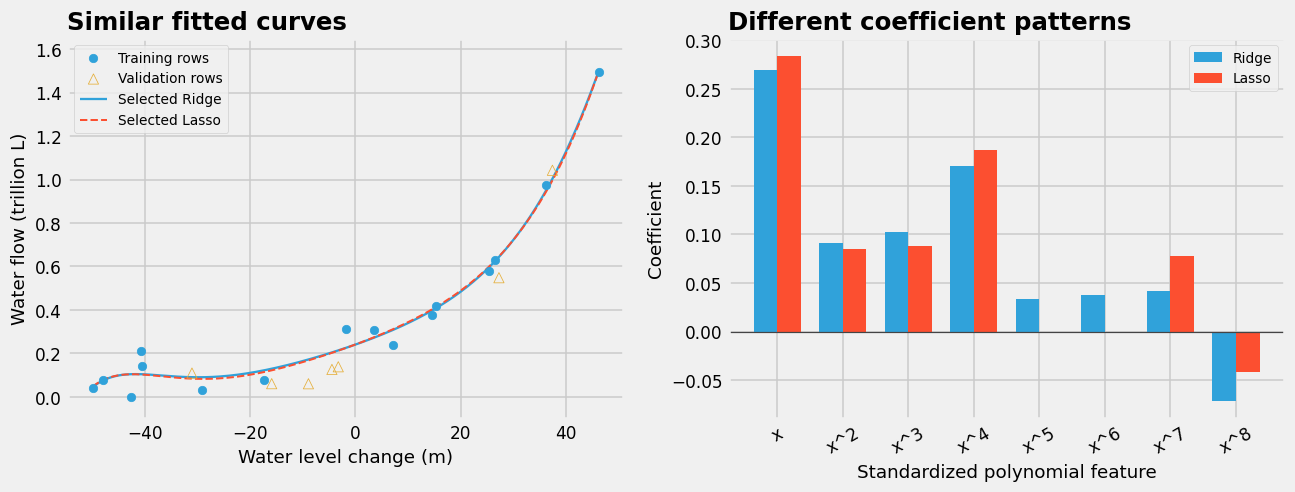

In [19]:
selected_lasso_curve = best_lasso.predict(X_grid_scaled)
plot_lasso_comparison(training, validation, x_grid, ridge_curves[best_alpha],
                      selected_lasso_curve, coefficient_comparison)
plt.show()

<p>The two selected models give similar fitted curves despite using different coefficient patterns. Their validation errors also differ only slightly on seven observations. The split supports comparing these candidates, not a universal preference for one penalty.</p>
<p>Takeaway: Ridge shrinks coefficients. Lasso also sets some coefficients exactly to zero, producing a model with fewer active features. Choose the penalty and its strength using validation evidence.</p>
<p>Return to the slides at Regularization for logistic regression.</p>

<a id="section5"></a>
<h2>5. Regularized Logistic Regression</h2>
<p>Question: How does regularization change predicted probabilities when the classification threshold stays fixed?</p>
<p>Return to the Week 7 NBA example. Each row describes a team in a completed game. The feature is the team's field-goal percentage minus its opponent's field-goal percentage. The target is 1 for a win and 0 for a loss. These final box scores support retrospective classification, not a forecast before the game.</p>
<p>Keep the two team rows from each game together when splitting. Fit a training scaler, then vary <code>C</code> in logistic regression. Smaller <code>C</code> means a stronger coefficient penalty. This direction is the reverse of <code>alpha</code> in Ridge and Lasso.</p>

In [20]:
nba = pd.read_csv('nba.csv')
paired = nba.merge(nba, on='GAME_ID', suffixes=('', '_OPP'))
paired = paired.loc[paired['TEAM_ID'] != paired['TEAM_ID_OPP']]
games = pd.DataFrame({
    'GAME_ID': paired['GAME_ID'],
    'FG_PCT_DIFF': paired['FG_PCT'] - paired['FG_PCT_OPP'],
    'WON': (paired['WL'] == 'W').astype(int),
}).reset_index(drop=True)
games.head()

,GAME_ID,FG_PCT_DIFF,WON
0,21700002,0.053,0
1,21700002,-0.053,1
2,21700001,-0.049,0
3,21700001,0.049,1
4,21700011,-0.026,0


<p>A positive feature value means the team made a larger fraction of its field-goal attempts than its opponent. Split by game ID so the opposing team never appears in the other set.</p>

In [21]:
train_game_ids, val_game_ids = train_test_split(
    games['GAME_ID'].unique(), test_size=0.25, random_state=RANDOM_STATE)
game_train = games.loc[games['GAME_ID'].isin(train_game_ids)]
game_validation = games.loc[games['GAME_ID'].isin(val_game_ids)]
assert set(train_game_ids).isdisjoint(val_game_ids)
game_scaler = StandardScaler()
game_X_train = game_scaler.fit_transform(game_train[['FG_PCT_DIFF']])
game_X_validation = game_scaler.transform(game_validation[['FG_PCT_DIFF']])
game_grid = pd.DataFrame({'FG_PCT_DIFF': np.linspace(-0.25, 0.25, 201)})
game_X_grid = game_scaler.transform(game_grid)
print('Training games:', len(train_game_ids), '| Training team rows:', len(game_train))
print('Validation games:', len(val_game_ids), '| Validation team rows:', len(game_validation))

Training games: 922 | Training team rows: 1844
Validation games: 308 | Validation team rows: 616


<p>Use the default L2 penalty and compare five values of <code>C</code>. Cross-entropy evaluates the predicted probabilities. Accuracy evaluates predicted classes using a threshold of 0.50. The fitting penalty is excluded from both reported metrics.</p>

In [22]:
c_values = [0.001, 0.01, 0.1, 1.0, 10.0]
logistic_rows = []
probability_curves = {}
for c_value in c_values:
    game_model = LogisticRegression(C=c_value, max_iter=2000)
    game_model.fit(game_X_train, game_train['WON'])
    train_probability = game_model.predict_proba(game_X_train)[:, 1]
    val_probability = game_model.predict_proba(game_X_validation)[:, 1]
    train_loss = log_loss(game_train['WON'], train_probability)
    val_loss = log_loss(game_validation['WON'], val_probability)
    val_accuracy = accuracy_score(game_validation['WON'], val_probability >= 0.5)
    logistic_rows.append([c_value, game_model.coef_[0, 0], train_loss, val_loss, val_accuracy])
    probability_curves[c_value] = game_model.predict_proba(game_X_grid)[:, 1]
logistic_results = pd.DataFrame(logistic_rows, columns=[
    'C', 'Coefficient', 'Training cross-entropy', 'Validation cross-entropy', 'Validation accuracy'])
logistic_results

,C,Coefficient,Training cross-entropy,Validation cross-entropy,Validation accuracy
0,0.001,0.405,0.585,0.582,0.784
1,0.010,1.323,0.459,0.457,0.784
2,0.100,2.103,0.429,0.433,0.784
3,1.000,2.305,0.428,0.434,0.784
4,10.000,2.330,0.428,0.434,0.784


<p>All five models have validation accuracy about 0.784. Their probability estimates differ. The stronger penalty at <code>C=0.001</code> gives a smaller coefficient and pulls probabilities toward 0.5. Each training game contributes one win and one loss, so half the training rows belong to the positive class. When the coefficients shrink to zero, an unpenalized intercept predicts the training positive-class fraction. That fraction need not be 0.5 in other datasets. Compare the curves and choose <code>C</code> using validation cross-entropy.</p>

Selected C: 0.1
Validation cross-entropy: 0.433


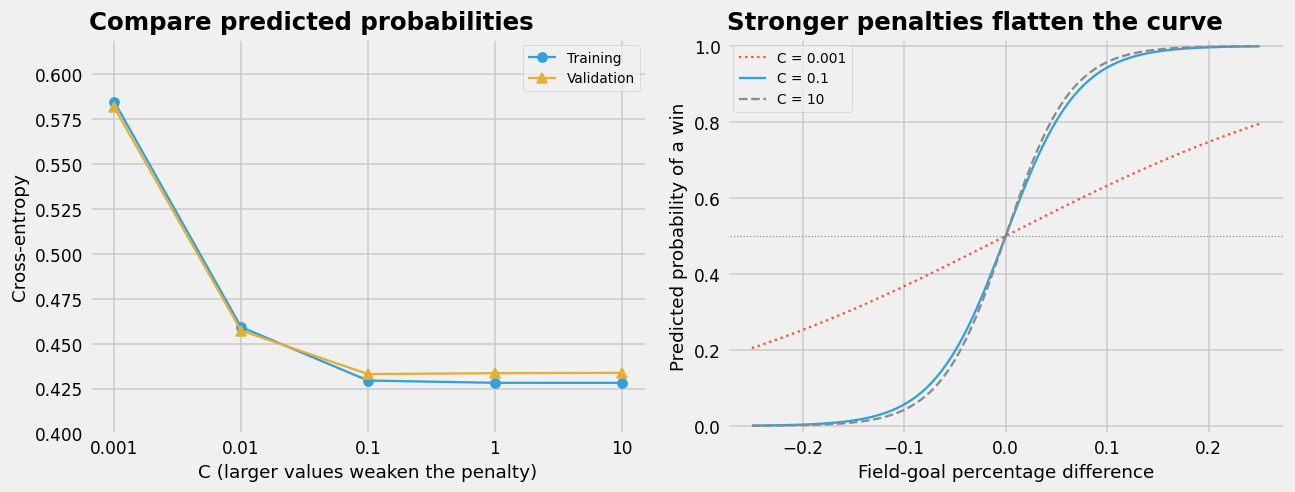

In [23]:
best_c_row = logistic_results.loc[logistic_results['Validation cross-entropy'].idxmin()]
best_c = float(best_c_row['C'])
print('Selected C:', best_c)
print('Validation cross-entropy:', round(best_c_row['Validation cross-entropy'], 3))
plot_logistic_regularization(logistic_results, game_grid, probability_curves)
plt.show()

<p>On this split, <code>C=0.1</code> gives the lowest validation cross-entropy, about 0.433. Identical accuracy does not imply identical probabilities. The coefficient controls how sharply the probability changes with the shooting-percentage difference.</p>
<p>Takeaway: Smaller <code>C</code> strengthens logistic regression's penalty. Choose the strength using a metric suited to the intended prediction. Probability quality and classification accuracy answer different questions.</p>
<p>Return to the slides at Applying regularization.</p>

<a id="section6"></a>
<h2>6. Evaluating Regularized Models</h2>
<p>Question: Why does a regularized model accept a larger training error?</p>
<p>Return to the selected degree 8 Ridge model. During fitting, Ridge balances squared prediction error against a coefficient penalty. During evaluation, RMSE measures prediction error alone.</p>
<p>Scikit-learn Ridge minimizes the sum of squared errors plus <code>alpha</code> times the sum of squared coefficients. Dividing the full objective by the number of training rows gives the equivalent form used here.</p>
<p>$J = \operatorname{MSE}_{\mathrm{train}} + \lambda\sum_j w_j^2$, where $\lambda = \alpha/n$.</p>
<p>Compare the unregularized and Ridge fits under this same objective, with the same selected penalty strength. Exclude the intercept from the penalty.</p>

In [24]:
ridge_lambda = best_alpha / len(training)
objective_rows = []
for label, fitted_model in [('Unregularized fit', unregularized), ('Ridge fit', best_ridge)]:
    training_mse = mean_squared_error(y_train, fitted_model.predict(X_train_scaled))
    coefficient_sum = np.sum(fitted_model.coef_**2)
    weighted_penalty = ridge_lambda * coefficient_sum
    objective = training_mse + weighted_penalty
    objective_rows.append([label, training_mse, weighted_penalty, objective])
objective_results = pd.DataFrame(objective_rows, columns=[
    'Fitted model', 'Training MSE', 'Weighted penalty', 'Same Ridge objective'])
print('Ridge lambda = alpha / training rows:', ridge_lambda)
objective_results

Ridge lambda = alpha / training rows: 0.00625


,Fitted model,Training MSE,Weighted penalty,Same Ridge objective
0,Unregularized fit,0.002,1.786e-01,0.181
1,Ridge fit,0.003,8.095e-04,0.004


<p>The unregularized fit has the smaller training MSE. Its much larger coefficients produce a larger penalty, so its value under the selected Ridge objective is much higher. Ridge accepts a small increase in training error to reduce the combined objective.</p>
<p>Lasso uses a different convention. Scikit-learn minimizes one-half of training MSE plus <code>alpha</code> times the sum of absolute coefficients. In an equivalent MSE-based form, the Lasso penalty weight is $2\alpha$. Objective values from different penalty types or strengths do not provide a common model-selection score.</p>
<h3>Compare prediction error without the penalty</h3>
<p>Use ordinary validation RMSE to compare the dam models. The values below use the same seven validation observations and the same water-flow units.</p>

In [25]:
prediction_rows = []
for label, fitted_model in [('Unregularized', unregularized),
                            ('Selected Ridge', best_ridge), ('Selected Lasso', best_lasso)]:
    training_rmse = mean_squared_error(y_train, fitted_model.predict(X_train_scaled))**0.5
    validation_rmse = mean_squared_error(y_validation, fitted_model.predict(X_validation_scaled))**0.5
    prediction_rows.append([label, training_rmse, validation_rmse])
prediction_comparison = pd.DataFrame(prediction_rows, columns=[
    'Model', 'Training RMSE (trillion L)', 'Validation RMSE (trillion L)'])
prediction_comparison

,Model,Training RMSE (trillion L),Validation RMSE (trillion L)
0,Unregularized,0.045,0.099
1,Selected Ridge,0.053,0.076
2,Selected Lasso,0.053,0.075


<p>Both selected penalties improve validation RMSE relative to the unregularized model on this split. Lasso's small advantage over Ridge rests on only seven validation observations. These comparisons guide a model choice. A separate final test set would be needed after fixing all choices to estimate performance without further tuning.</p>
<p>Takeaway: The penalty guides fitting. Use ordinary prediction metrics to compare models on validation data, and reserve final-test data for the completed procedure.</p>
<p>Return to the slides for the lecture summary.</p>
<a id="summary"></a>
<h2>Lecture summary</h2>
<ul>
<li>Polynomial features increase the range of shapes a model represents.</li>
<li>Training-fitted standardization keeps arbitrary feature units from changing the penalty comparison.</li>
<li>Ridge shrinks coefficients. Lasso also removes features by setting coefficients to zero.</li>
<li>Larger alpha strengthens Ridge and Lasso penalties. Smaller C strengthens logistic regression's penalty.</li>
<li>Choose models using validation prediction metrics, without adding the fitting penalty.</li>
</ul>